In [2]:
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
import cv2
from config import CLASS_IDS,TRAIN_IMG_DIR,TRAIN_MASK_DIR,CLASS_LABELS,VAL_IMG_DIR,VAL_MASK_DIR,TEST_IMG_DIR,TEST_MASK_DIR
BATCH_SIZE=2

In [3]:
WIDTH=960
HEIGHT=544

# WIDTH=512
# HEIGHT=512

# WIDTH=768
# HEIGHT=448

# WIDTH=960
# HEIGHT=540

In [4]:
def remap_mask(mask):
    #logging.info(mask[0])  
    print(type(mask))  
    print(mask.shape)  
    mask = tf.expand_dims(mask, -1)                  # (H,W,1)
    eq = tf.equal(mask, CLASS_IDS)                   # (H,W,C)
    mask = tf.argmax(tf.cast(eq, tf.int32), axis=-1) # (H,W)
    return mask

def load_image_and_mask(image_path,mask_path):
    image=tf.io.read_file(image_path)
    image=tf.image.decode_png(image,channels=3)
    image=tf.image.resize(image,(HEIGHT,WIDTH),method="bilinear")
    image=tf.cast(image,tf.float32)/255.0

    mask=tf.io.read_file(mask_path)
    mask=tf.image.decode_png(mask,channels=1,dtype=tf.uint16)
    mask=tf.image.resize(mask,(HEIGHT,WIDTH),method="nearest")
    mask=tf.squeeze(mask,axis=-1)
    mask = remap_mask(mask)
    mask=tf.cast(mask,tf.int32)
    print ("Load image and mask function started ")
    print("image",type(image))  
    print("image shape:",image.shape) 

    print("mask type:",type(mask))  
    print("mask shape:",mask.shape) 
    print ("Load image and mask function ended")

    return image,mask
def get_sorted_file_paths(image_dir,mask_dir):
    image_files=sorted([os.path.join(image_dir,f)
                        for f in os.listdir(image_dir)
                        if f.endswith(".png")
                        ])
    mask_files=sorted([os.path.join(mask_dir,f)
                       for f in os.listdir(mask_dir)
                       if f.endswith(".png")
                       ])
    return image_files,mask_files

def augment_pair(image,mask):
    seed=tf.random.experimental.stateless_split(tf.random.uniform([2], maxval=1000, dtype=tf.int32), num=1)[0]
    if tf.random.uniform(())>0.5:
        image=tf.image.stateless_random_flip_left_right(image,seed)
        mask=tf.image.stateless_random_flip_left_right(tf.expand_dims(mask, -1),seed)
        mask=tf.squeeze(mask,axis=-1)

    image=tf.image.random_brightness(image,max_delta=0.3)
    image=tf.image.random_contrast(image,lower=0.8,upper=1.2)
    image=tf.image.random_saturation(image,lower=0.8,upper=1.2)

    image=tf.clip_by_value(image,0.0,1.0)

    return image,mask

def build_dataset(image_dir, mask_dir,isTrainingDataset=True,performAugment=True):
    image_paths,mask_paths=get_sorted_file_paths(image_dir, mask_dir)
    dataset=tf.data.Dataset.from_tensor_slices(
        (image_paths,mask_paths)
    )
    if isTrainingDataset:
        dataset=dataset.shuffle(buffer_size=256)
    dataset=dataset.map(
        load_image_and_mask,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    if isTrainingDataset and performAugment:
        dataset=dataset.map(
            augment_pair,num_parallel_calls=tf.data.AUTOTUNE
        )
    dataset=dataset.batch(BATCH_SIZE)
    dataset=dataset.prefetch(tf.data.AUTOTUNE)
    return dataset

In [12]:
def check_detail_loss(original_mask, resized_mask):
    if hasattr(resized_mask, 'numpy'):
        resized_mask_np = resized_mask.numpy()
    else:
        resized_mask_np = resized_mask
        
    if hasattr(original_mask, 'numpy'):
        original_mask_np = original_mask.numpy()
    else:
        original_mask_np = original_mask
    print("got shape of the mask:",resized_mask.shape)
    reconstructed = cv2.resize(
        resized_mask_np.astype('uint8'), 
        (960, 544), 
        interpolation=cv2.INTER_NEAREST
    )
    error_map = np.where(original_mask_np != reconstructed, 1, 0)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(original_mask_np)
    ax[0].set_title("Original (960x540)")
    
    ax[1].imshow(reconstructed)
    ax[1].set_title("Reconstructed from Resize")
    
    ax[2].imshow(error_map, cmap='Reds')
    ax[2].set_title("Detail Loss (Red = Error)")
    
    plt.show()

    loss_percent = (np.sum(error_map) / (960 * 540)) * 100
    print(f"Total Detail Loss: {loss_percent:.2f}%")

In [ ]:
ds=build_dataset(image_dir=TRAIN_IMG_DIR,mask_dir=TRAIN_MASK_DIR,isTrainingDataset=False,performAugment=False)
it=iter(ds)

<class 'tensorflow.python.framework.ops.Tensor'>
(544, 960)
Load image and mask function started 
image <class 'tensorflow.python.framework.ops.Tensor'>
image shape: (544, 960, 3)
mask type: <class 'tensorflow.python.framework.ops.Tensor'>
mask shape: (544, 960)
Load image and mask function ended


(2, 544, 960, 3) (2, 544, 960)


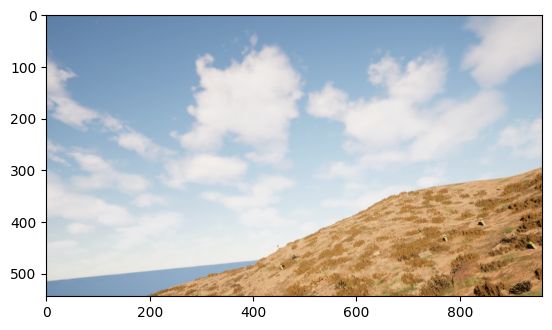

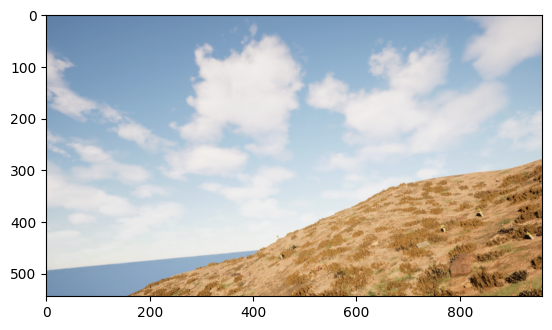

In [ ]:
img_batch,msk_batch=next(it)
print(img_batch.shape,msk_batch.shape)

for i in range(BATCH_SIZE):
    plt.imshow(img_batch[i])
    plt.show()

<class 'tensorflow.python.framework.ops.Tensor'>
(544, 960)
Load image and mask function started 
image <class 'tensorflow.python.framework.ops.Tensor'>
image shape: (544, 960, 3)
mask type: <class 'tensorflow.python.framework.ops.Tensor'>
mask shape: (544, 960)
Load image and mask function ended
(2, 544, 960, 3) (2, 544, 960)


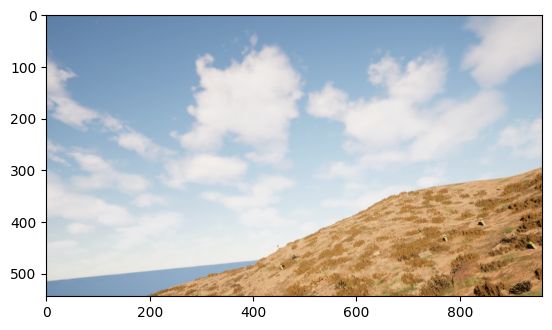

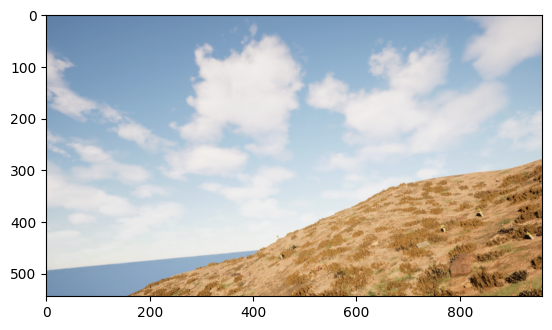

got shape of the mask: (544, 960)


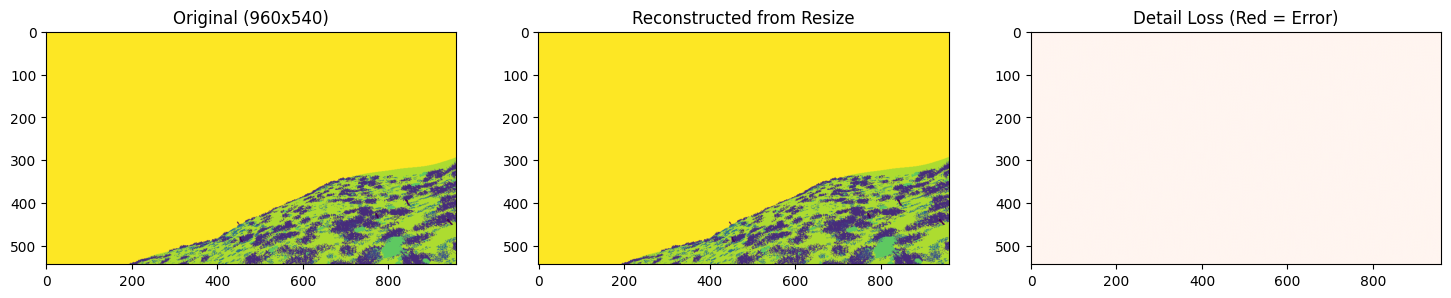

Total Detail Loss: 0.00%
got shape of the mask: (544, 960)


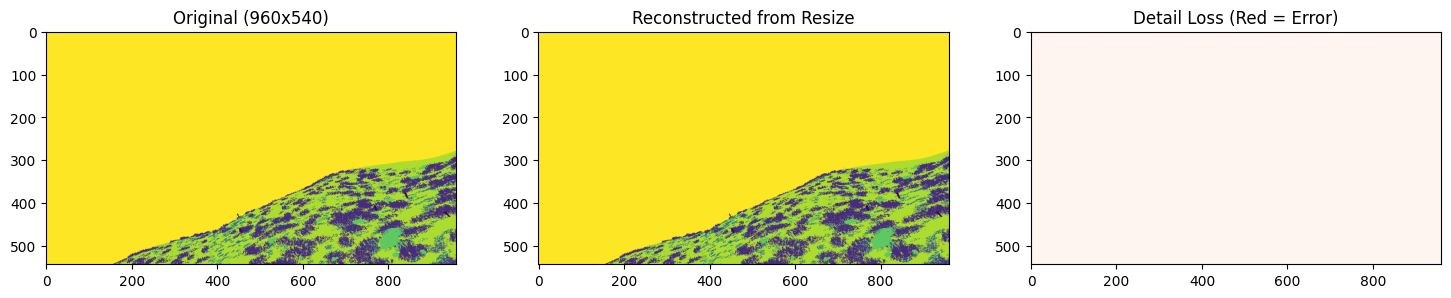

Total Detail Loss: 0.00%


In [ ]:
#768*448
dsn=build_dataset(TRAIN_IMG_DIR,TRAIN_MASK_DIR,isTrainingDataset=False,performAugment=False)
itn=iter(dsn)
img_batch_new,mask_batch_new=next(itn)
print(img_batch_new.shape,mask_batch_new.shape)
for i in range(BATCH_SIZE):
    plt.imshow(img_batch_new[i])
    plt.show()
for i in range(BATCH_SIZE):
    check_detail_loss(msk_batch[i],mask_batch_new[i])
    print("=====================================================================================================================================")

In [5]:
train_ds=build_dataset(image_dir=TRAIN_IMG_DIR,mask_dir=TRAIN_MASK_DIR,isTrainingDataset=False,performAugment=False)
val_ds=build_dataset(image_dir=VAL_IMG_DIR,mask_dir=VAL_MASK_DIR,isTrainingDataset=False,performAugment=False)
test_ds=build_dataset(image_dir=TEST_IMG_DIR,mask_dir=TEST_MASK_DIR,isTrainingDataset=False,performAugment=False)

<class 'tensorflow.python.framework.ops.Tensor'>
(544, 960)
Load image and mask function started 
image <class 'tensorflow.python.framework.ops.Tensor'>
image shape: (544, 960, 3)
mask type: <class 'tensorflow.python.framework.ops.Tensor'>
mask shape: (544, 960)
Load image and mask function ended
<class 'tensorflow.python.framework.ops.Tensor'>
(544, 960)
Load image and mask function started 
image <class 'tensorflow.python.framework.ops.Tensor'>
image shape: (544, 960, 3)
mask type: <class 'tensorflow.python.framework.ops.Tensor'>
mask shape: (544, 960)
Load image and mask function ended
<class 'tensorflow.python.framework.ops.Tensor'>
(544, 960)
Load image and mask function started 
image <class 'tensorflow.python.framework.ops.Tensor'>
image shape: (544, 960, 3)
mask type: <class 'tensorflow.python.framework.ops.Tensor'>
mask shape: (544, 960)
Load image and mask function ended


In [7]:
def get_pixel_counts(dataset):
    counts=np.zeros(len(CLASS_LABELS),dtype=np.int64)
    for _,mask_batch in dataset:
        flat_mask=mask_batch.numpy().flatten()
        counts+=np.bincount(flat_mask,minlength=len(CLASS_LABELS))
    return counts

train_counts = get_pixel_counts(train_ds)
val_counts = get_pixel_counts(val_ds)
test_counts = get_pixel_counts(test_ds)

eda_df = pd.DataFrame({
    'Label': CLASS_LABELS,
    'Train %': (train_counts / train_counts.sum()) * 100,
    'Val %': (val_counts / val_counts.sum()) * 100,
    'Test %': (test_counts / test_counts.sum()) * 100
}).set_index('Label')

eda_df_pixel_count = pd.DataFrame({
    'Label': CLASS_LABELS,
    'Train %': train_counts,
    'Val %': val_counts ,
    'Test %': test_counts
}).set_index('Label')


print(eda_df)
print("======================================")
print(eda_df_pixel_count)


                  Train %      Val %     Test %
Label                                          
Trees            3.529683   4.063176   0.269498
Lush Bushes      5.933981   6.014540   0.001479
Dry Grass       18.872895  19.344905  17.373509
Dry Bushes       1.099030   1.099044   3.045014
Ground Clutter   4.394827   4.239041   0.000000
Flower           2.807256   2.435103   0.000000
Logs             0.078129   0.066852   0.000000
Rocks            1.198249   1.213580  18.131278
Landscape       24.447772  23.767870  43.184236
Sky             37.638177  37.755889  17.994986
                  Train %     Val %     Test %
Label                                         
Trees            52664278   6726591    1410240
Lush Bushes      88537357   9957075       7739
Dry Grass       281591086  32025506   90912878
Dry Bushes       16397969   1819469   15934086
Ground Clutter   65572565   7017736          0
Flower           41885367   4031315          0
Logs              1165718    110673          0
R

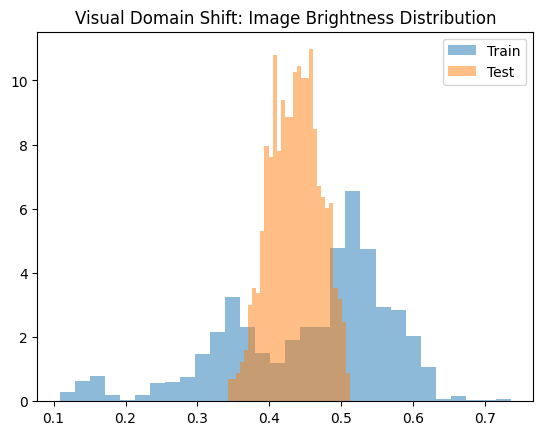

In [21]:
def get_intensity_stats(dataset):
    means = []
    for img_batch, _ in dataset:
        means.append(np.mean(img_batch.numpy(), axis=(1, 2, 3)))
    return np.concatenate(means)

train_intensities = get_intensity_stats(train_ds)
test_intensities = get_intensity_stats(test_ds)

plt.hist(train_intensities, bins=30, alpha=0.5, label='Train', density=True)
plt.hist(test_intensities, bins=30, alpha=0.5, label='Test', density=True)
plt.title("Visual Domain Shift: Image Brightness Distribution")
plt.legend()
plt.show()

In [24]:
from skimage.feature import graycomatrix, graycoprops
import numpy as np
import pandas as pd

def extract_texture_features(dataset, num_samples=50):
    features = {prop: [] for prop in ['contrast', 'correlation', 'energy', 'homogeneity']}
    
    for img_batch, _ in dataset.take(num_samples):
        # Convert to grayscale for texture analysis
        # img_batch is (B, 544, 960, 3), we'll take the first image in batch
        img = tf.image.rgb_to_grayscale(img_batch[0]).numpy()
        
        # Scale to 0-255 uint8 as required by skimage
        img_uint8 = (img * 255).astype(np.uint8).squeeze()
        
        # Calculate GLCM (looking 5 pixels away to the right)
        glcm = graycomatrix(img_uint8, distances=[5], angles=[0], 
                            levels=256, symmetric=True, normed=True)
        
        for prop in features.keys():
            features[prop].append(graycoprops(glcm, prop)[0, 0])
            
    return pd.DataFrame(features)

# Run for both
train_texture = extract_texture_features(train_ds)
test_texture = extract_texture_features(test_ds)

In [25]:
print(test_texture)

       contrast  correlation    energy  homogeneity
0   1067.549217     0.785086  0.011575     0.117305
1   1141.865992     0.774536  0.011736     0.118412
2   1074.407705     0.782797  0.011780     0.119469
3    955.630116     0.800001  0.011844     0.120021
4   1036.084944     0.802932  0.011348     0.119131
5   1080.671291     0.798131  0.011373     0.120358
6   1026.317397     0.804518  0.011702     0.123237
7    967.401353     0.809175  0.012027     0.126613
8    933.002096     0.796149  0.012498     0.128087
9    875.985123     0.805934  0.012596     0.128480
10   948.183452     0.802167  0.012287     0.126903
11  1042.758508     0.798807  0.012130     0.127022
12  1018.194453     0.810749  0.012142     0.127100
13  1041.281439     0.811446  0.011888     0.126460
14  1116.692890     0.803311  0.011752     0.126905
15  1156.695244     0.796508  0.011835     0.128744
16  1128.861320     0.808584  0.012189     0.133063
17  1072.424332     0.814061  0.012281     0.134798
18  1036.579

C:\Users\hp\AppData\Local\Temp\ipykernel_29688\484350784.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='Set', y=col, ax=axes[i], palette="muted")
C:\Users\hp\AppData\Local\Temp\ipykernel_29688\484350784.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='Set', y=col, ax=axes[i], palette="muted")
C:\Users\hp\AppData\Local\Temp\ipykernel_29688\484350784.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=combined_df, x='Set', y=col, ax=axes[i], palette="muted")
C:\Users\hp\AppData\Local\Te

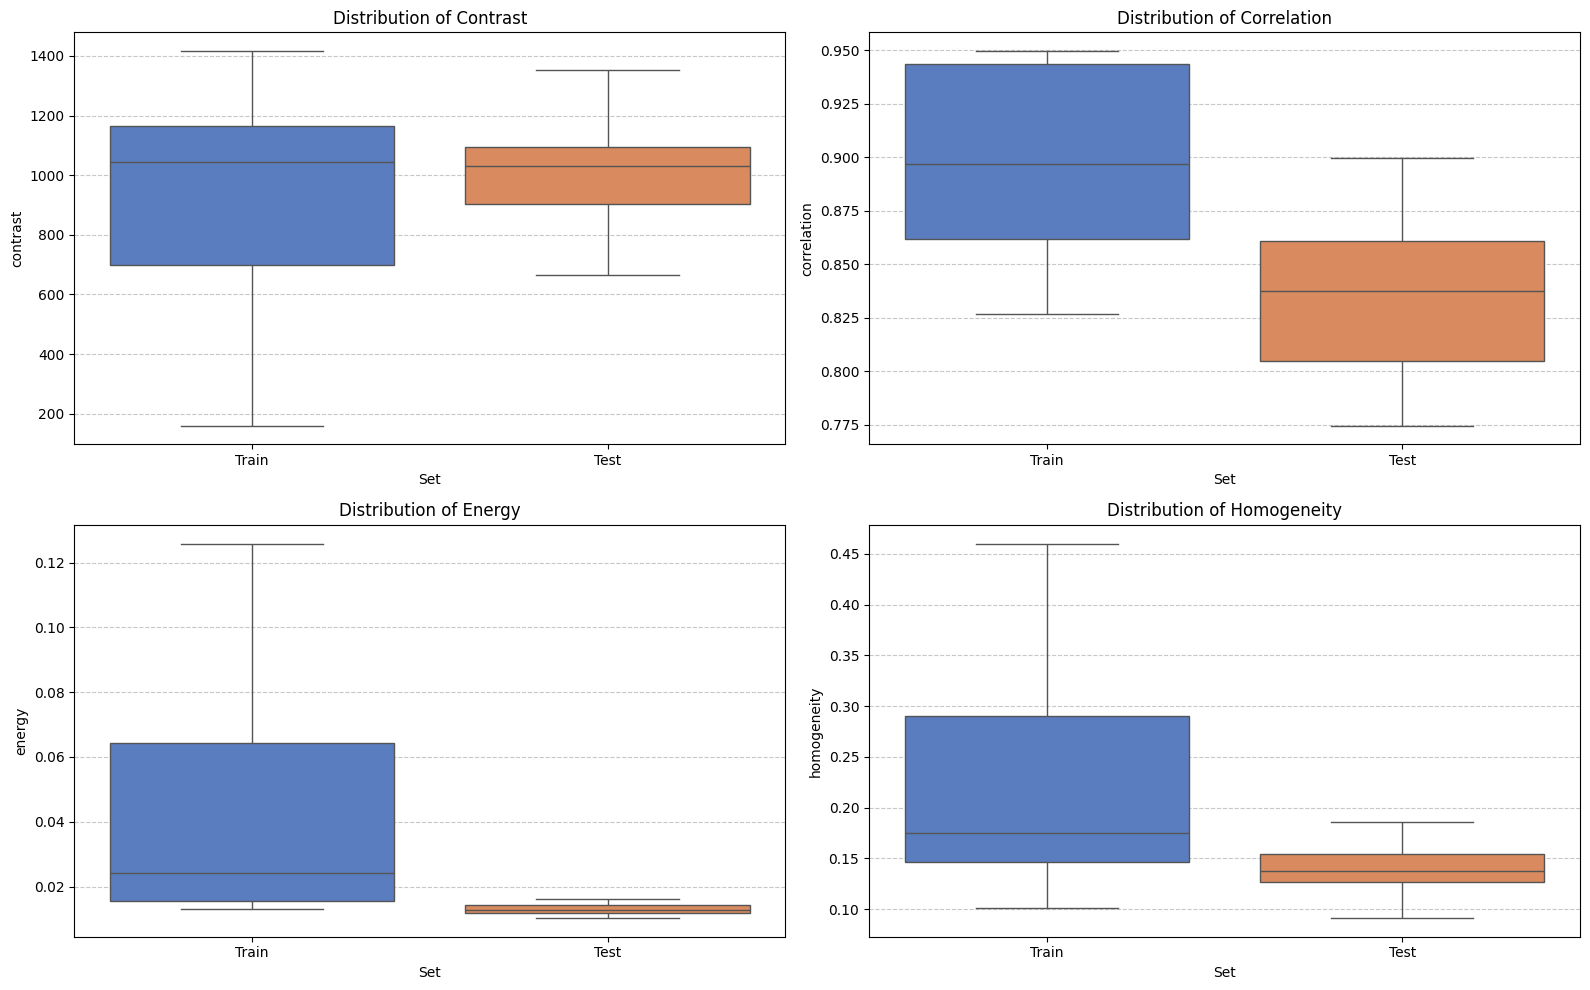

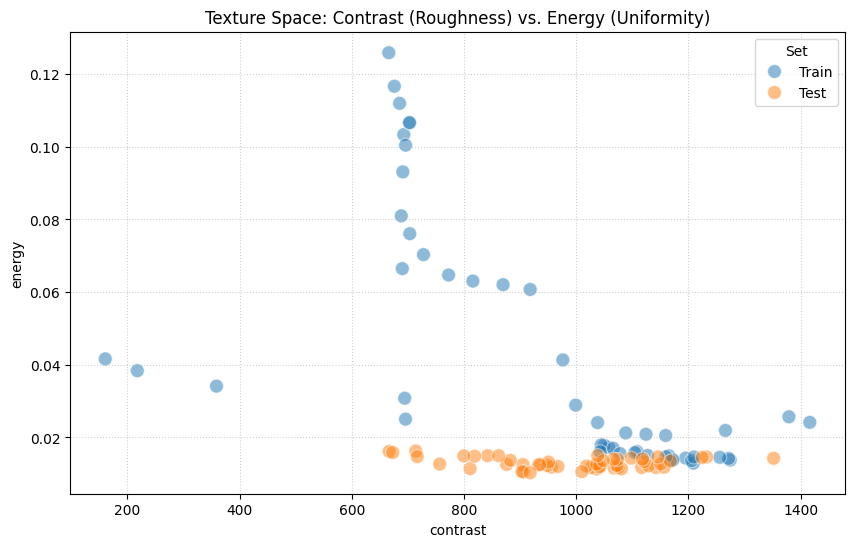

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prepare data for plotting
train_texture['Set'] = 'Train'
test_texture['Set'] = 'Test'
combined_df = pd.concat([train_texture, test_texture])

# 2. Box Plots: Do the distributions match?
features = ['contrast', 'correlation', 'energy', 'homogeneity']
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=combined_df, x='Set', y=col, ax=axes[i], palette="muted")
    axes[i].set_title(f'Distribution of {col.capitalize()}')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('texture_boxplots.png')

# 3. Scatter Plot: The "Texture Space"
# Contrast vs. Energy is the best way to see the "Roughness" of the biome
plt.figure(figsize=(10, 6))
sns.scatterplot(data=combined_df, x='contrast', y='energy', hue='Set', alpha=0.5, s=100)
plt.title('Texture Space: Contrast (Roughness) vs. Energy (Uniformity)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('texture_scatter.png')

In [28]:
from skimage import measure
import pandas as pd
import numpy as np

def measure_average_object_sizes(dataset, class_labels, class_indices):
    object_stats = []

    print("Measuring objects across dataset...")
    for _, mask_batch in dataset.take(100): # Sample 100 batches for a deep audit
        masks = mask_batch.numpy()
        
        for m in range(masks.shape[0]):
            current_mask = masks[m]
            
            for idx, label in zip(class_indices, class_labels):
                # Create a binary mask for this specific class
                binary_mask = (current_mask == idx).astype(np.uint8)
                
                # Label connected components (objects)
                blobs = measure.label(binary_mask)
                properties = measure.regionprops(blobs)
                
                for prop in properties:
                    object_stats.append({
                        'Class': label,
                        'Area_Pixels': prop.area,
                        'Equivalent_Diameter': prop.equivalent_diameter
                    })

    df = pd.DataFrame(object_stats)
    return df

# Run the measurement
# Use the indices 0-9 since you already have a remap_mask function
class_indices = list(range(len(CLASS_LABELS)))
df_sizes = measure_average_object_sizes(train_ds, CLASS_LABELS, class_indices)

Measuring objects across dataset...


In [29]:
summary = df_sizes.groupby('Class')['Area_Pixels'].agg(['mean', 'median', 'std', 'max', 'count'])
print(summary.sort_values(by='mean'))

                        mean  median           std       max    count
Class                                                                
Ground Clutter      8.593220     2.0     44.446098    3813.0   426080
Dry Bushes         21.961125     1.0    362.576538   27280.0   208744
Rocks              24.267058     2.0    231.315109   10597.0    70247
Landscape          27.817899     1.0   1645.422149  205887.0  1089631
Lush Bushes        30.394144     1.0    136.336877    3976.0     7104
Dry Grass          63.697840     1.0   2072.899087  186825.0   490704
Sky             14010.154176     1.0  54564.816557  416541.0     2335


In [31]:
test_df_sizes = measure_average_object_sizes(test_ds, CLASS_LABELS, class_indices)
summary = test_df_sizes.groupby('Class')['Area_Pixels'].agg(['mean', 'median', 'std', 'max', 'count'])
print(summary.sort_values(by='mean'))

Measuring objects across dataset...
                    mean  median           std       max    count
Class                                                            
Lush Bushes     6.857627     2.0     21.386096     219.0      590
Trees          15.752852     2.0     88.224420    3542.0    10605
Dry Grass      16.434944     1.0    649.498716  100755.0  1114638
Rocks          27.019026     2.0    431.118937  117716.0   695829
Dry Bushes     33.096755     1.0    848.693653   97580.0   123714
Landscape      56.876574     2.0   2787.642924  266790.0   740308
Sky          2766.540594     1.0  17094.046516  156717.0     7575
